In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from seq_minmax_opt_class import SeqMinMaxOptProb


from minmax_opt_class_mgnn import MinMaxOptProb

In [2]:
def u0(x):
    return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 0
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return 0
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x


t_min = 0
t_max = 1
x_min = -1
x_max = 1

In [3]:
notes = '''This notebook is for computing Burgers equation with sin init, \n
featured with initial gamma = 0.1, f_opt_kh = 1, use_a = True, and L1reg = 0.1.\n
We use warmup_exponential_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 1.
In this copy, we train 5000 epoches. '''
print(notes)

This notebook is for computing Burgers equation with sin init, 

featured with initial gamma = 0.1, f_opt_kh = 1, use_a = True, and L1reg = 0.1.

We use warmup_exponential_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 1.
In this copy, we train 5000 epoches. 


In [4]:
N_t = 16
N_x = 16
seq_trainer = SeqMinMaxOptProb(
    num_segments=2,
    total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
    N_t=N_t, N_x=N_x, N_bc=2048, N_ic=4096,
    hidden_dims_list=[[128, 128, 128, 128]], seed=0,
    sigma=1, N_perturb=100000, k_h_rf_times=1, f_opt_kh=1,
    u0=u0, u1=vmap_u1, u2=vmap_u2, project="seq_minmax_burgers_sin_wave",
    gamma=0.1, N_test_gamma=1000, adjust_gamma=False,
    L1reg=0.1, sampling_method='normal', notes=notes, lambda_tv=20.0, N_t_pnts = 5*N_t, N_x_pnts = 80*N_x,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
    res=res, total_grade=1, k=0,
    set_wandb=False
)


Adding grade 1 with hidden dims [128, 128, 128, 128]

Plotting before training segment [0.0000, 0.5000]


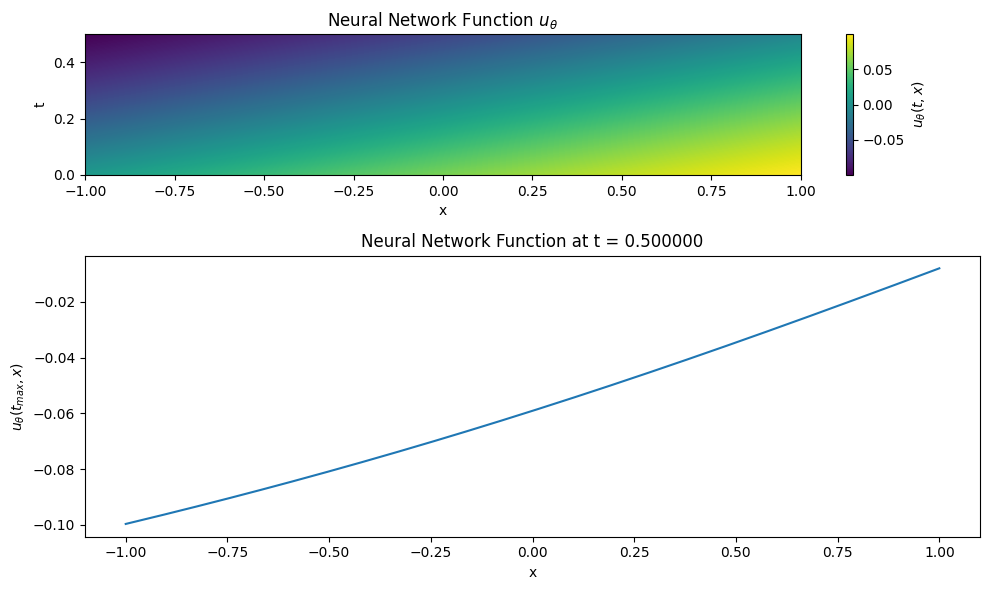


Training segment [0.0000, 0.5000]

Pre-training the network to fit v(t, x) = u0(x)
Pre-training Iter 0, Loss: 0.539373
Pre-training Iter 100, Loss: 0.018784
Pre-training Iter 200, Loss: 0.002890
Pre-training Iter 300, Loss: 0.001956
Pre-training Iter 400, Loss: 0.000982
Pre-training Iter 500, Loss: 0.002838
Pre-training Iter 600, Loss: 0.000501
Pre-training Iter 700, Loss: 0.002251
Pre-training Iter 800, Loss: 0.000286
Pre-training Iter 900, Loss: 0.002472
The pre-train to fit initial finished.

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 1.043920, loss_eqn_from_kh: 0.975383, loss_eqn_abs: 0.975383, loss_ibc: 0.000975


KeyboardInterrupt: 

In [5]:
seq_trainer.train_seq()

Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.0000, 0.5000]


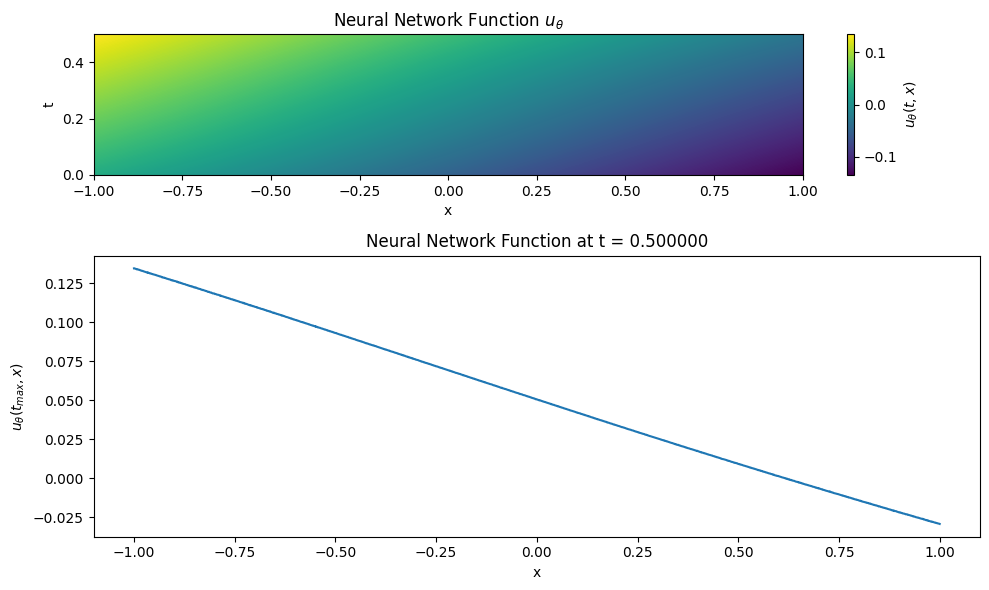


Training segment [0.0000, 0.5000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 0.205349, loss_eqn_from_kh: 0.204636, loss_eqn_abs: 0.204636, loss_ibc: 0.467140
Grade 0, Iter 100, loss_eqn: 0.560959, loss_eqn_from_kh: 0.551610, loss_eqn_abs: 0.551611, loss_ibc: 0.049799
Grade 0, Iter 200, loss_eqn: 0.394804, loss_eqn_from_kh: 0.391837, loss_eqn_abs: 0.391838, loss_ibc: 0.009251
Grade 0, Iter 300, loss_eqn: 0.266568, loss_eqn_from_kh: 0.261986, loss_eqn_abs: 0.261987, loss_ibc: 0.008113
Grade 0, Iter 400, loss_eqn: 0.220464, loss_eqn_from_kh: 0.207591, loss_eqn_abs: 0.207592, loss_ibc: 0.006605
Grade 0, Iter 500, loss_eqn: 0.182809, loss_eqn_from_kh: 0.167835, loss_eqn_abs: 0.167837, loss_ibc: 0.004832
Grade 0, Iter 600, loss_eqn: 0.155245, loss_eqn_from_kh: 0.141593, loss_eqn_abs: 0.141610, loss_ibc: 0.005613
Grade 0, Iter 700, loss_eqn: 0.127653, loss_eqn_from_kh: 0.115460, loss_eqn_abs: 0.115809, loss_ibc: 0.006365
G

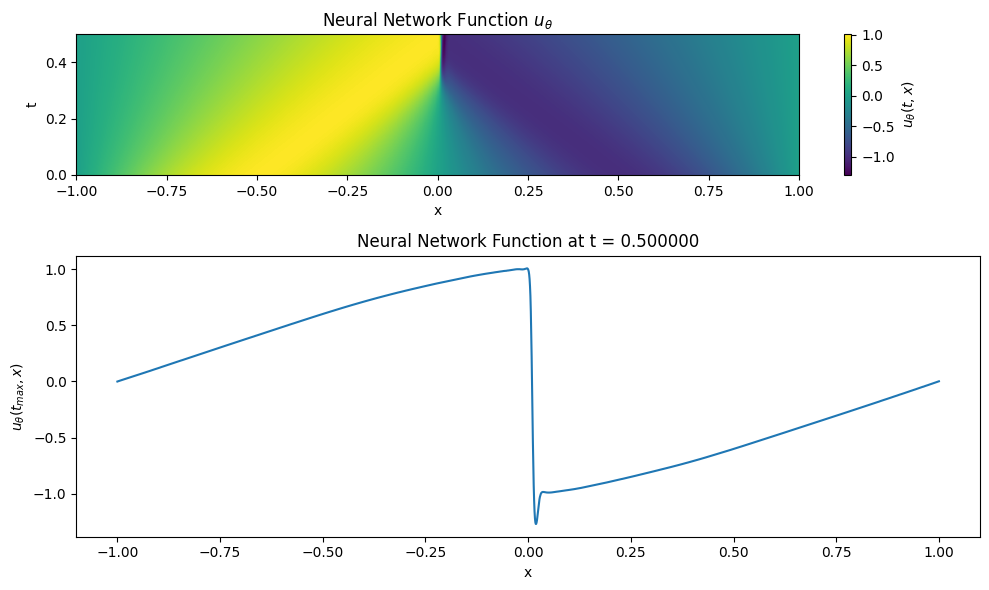

Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.5000, 1.0000]


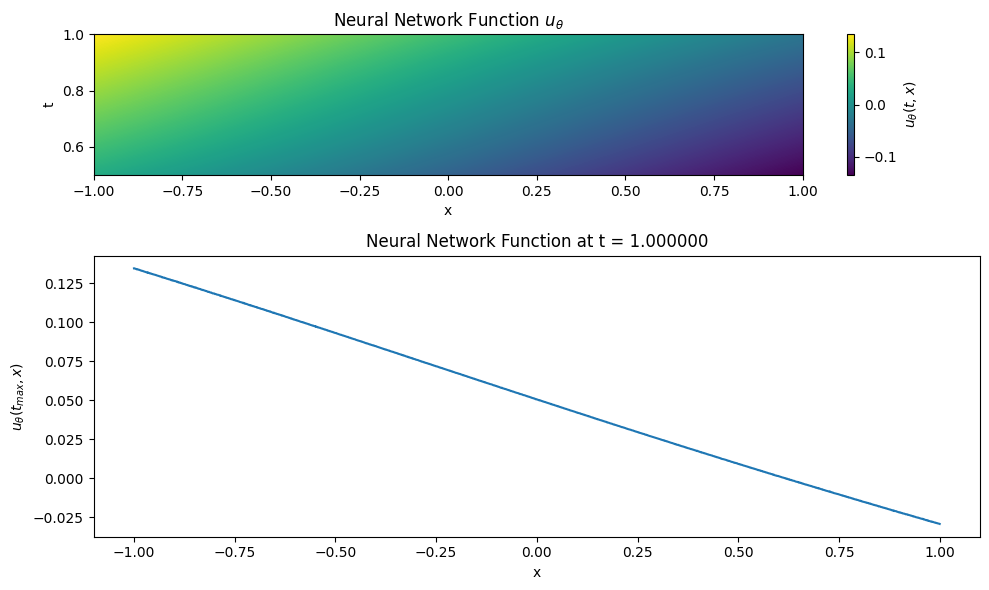


Training segment [0.5000, 1.0000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 0.205286, loss_eqn_from_kh: 0.204573, loss_eqn_abs: 0.204573, loss_ibc: 0.404074
Grade 0, Iter 100, loss_eqn: 0.532621, loss_eqn_from_kh: 0.521313, loss_eqn_abs: 0.521313, loss_ibc: 0.070484
Grade 0, Iter 200, loss_eqn: 0.379270, loss_eqn_from_kh: 0.378000, loss_eqn_abs: 0.378111, loss_ibc: 0.021547
Grade 0, Iter 300, loss_eqn: 0.323176, loss_eqn_from_kh: 0.321725, loss_eqn_abs: 0.360084, loss_ibc: 0.012883
Grade 0, Iter 400, loss_eqn: 0.225259, loss_eqn_from_kh: 0.224024, loss_eqn_abs: 0.393905, loss_ibc: 0.005825
Grade 0, Iter 500, loss_eqn: 0.145254, loss_eqn_from_kh: 0.143872, loss_eqn_abs: 0.397932, loss_ibc: 0.003860
Grade 0, Iter 600, loss_eqn: 0.089214, loss_eqn_from_kh: 0.087339, loss_eqn_abs: 0.451103, loss_ibc: 0.001784
Grade 0, Iter 700, loss_eqn: 0.092537, loss_eqn_from_kh: 0.090743, loss_eqn_abs: 0.511831, loss_ibc: 0.001034
G

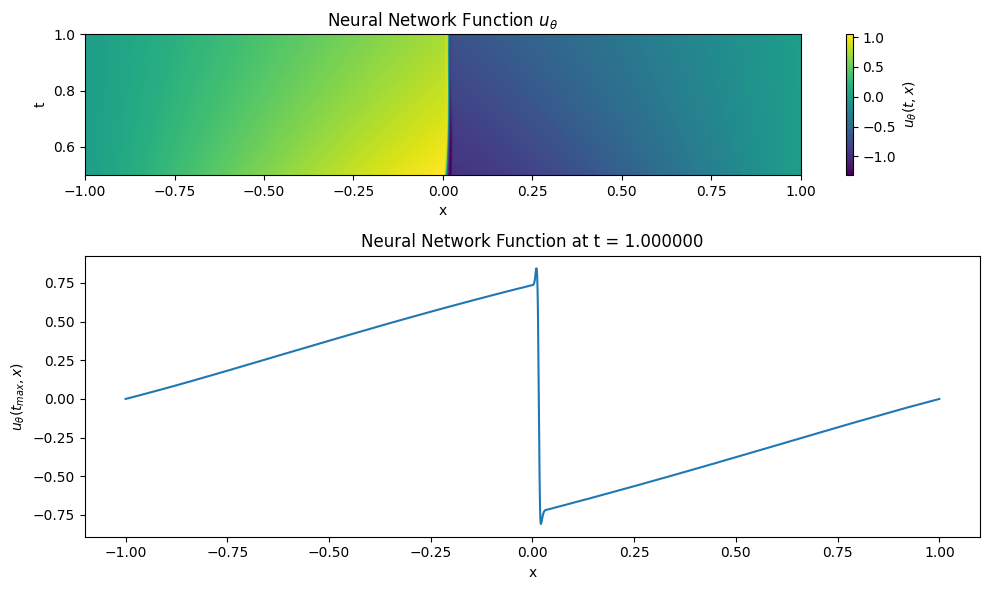


Plotting combined output across all segments from t=0 to total_t_max


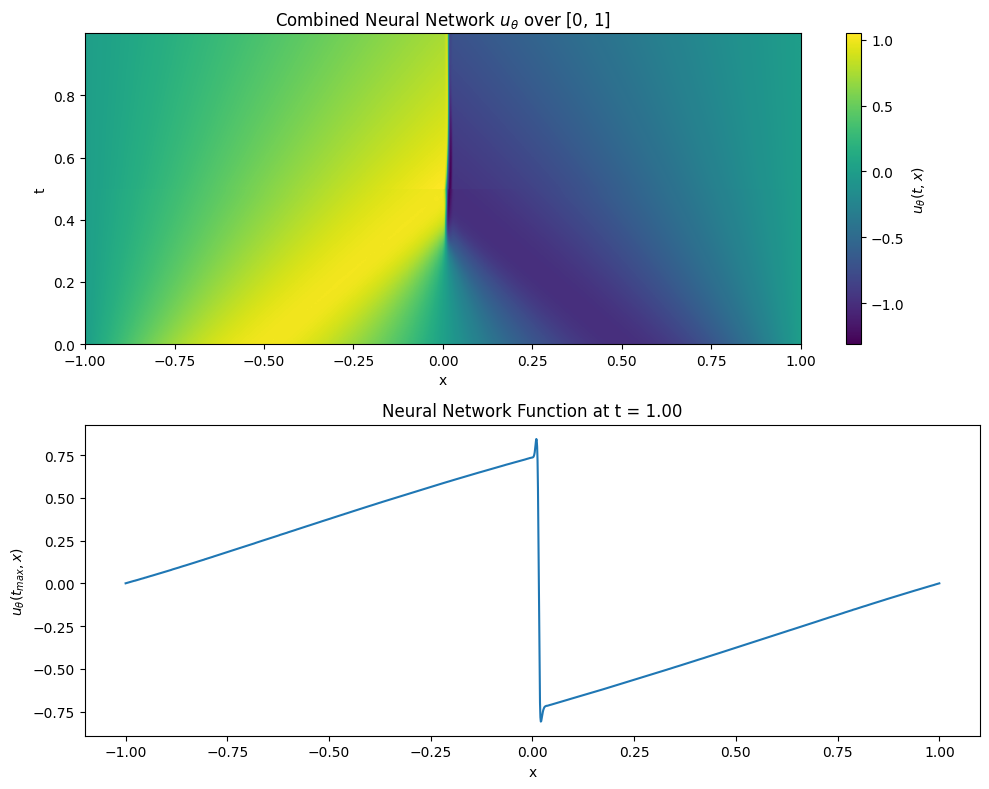

step,▁▁▁▂▂▃▃▃▃▄▅▅▅▅▆▆▇▇██▁▂▂▂▂▃▃▄▅▅▅▅▆▆▆▇▇▇▇█
tmin0.0_tmax0.5_loss_eqn_grade0,▃█▆▄▄▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.0_tmax0.5_loss_ibc_grade0,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_eqn_grade0,█▆▅▄▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_ibc_grade0,█▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,4900
tmin0.0_tmax0.5_loss_eqn_grade0,0.01556
tmin0.0_tmax0.5_loss_ibc_grade0,0.0002
tmin0.5_tmax1.0_loss_eqn_grade0,0.00634
tmin0.5_tmax1.0_loss_ibc_grade0,0.00019


In [ ]:
seq_trainer.train_seq()

Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.0000, 0.5000]


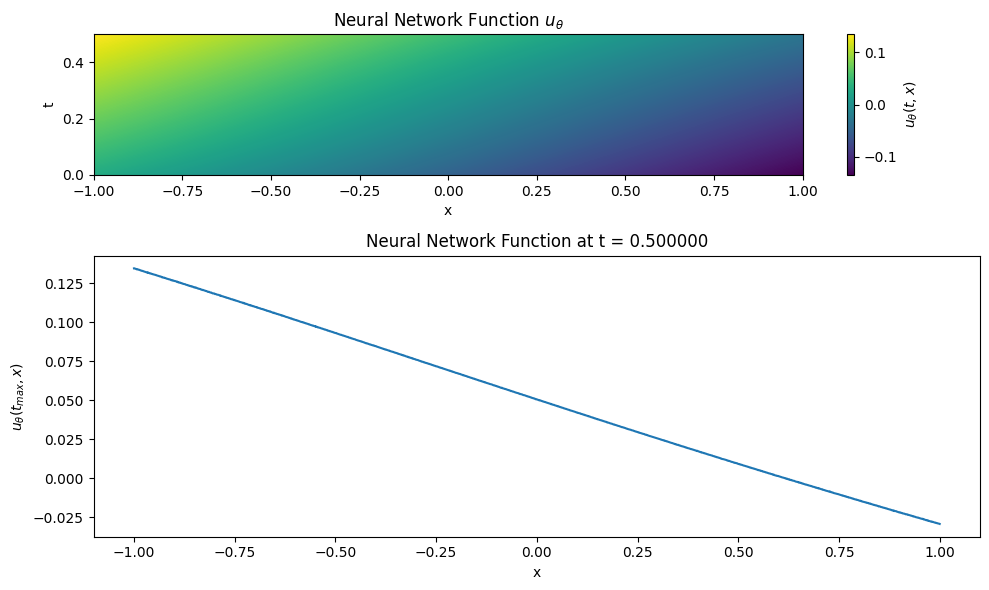


Training segment [0.0000, 0.5000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 0.204637, loss_eqn_from_kh: 0.204636, loss_eqn_abs: 0.204636, loss_ibc: 0.467140
Grade 0, Iter 100, loss_eqn: 0.536331, loss_eqn_from_kh: 0.536317, loss_eqn_abs: 0.536317, loss_ibc: 0.049528
Grade 0, Iter 200, loss_eqn: 0.372386, loss_eqn_from_kh: 0.372369, loss_eqn_abs: 0.372372, loss_ibc: 0.008679
Grade 0, Iter 300, loss_eqn: 0.247993, loss_eqn_from_kh: 0.247969, loss_eqn_abs: 0.247970, loss_ibc: 0.008688
Grade 0, Iter 400, loss_eqn: 0.196765, loss_eqn_from_kh: 0.196711, loss_eqn_abs: 0.196713, loss_ibc: 0.006674
Grade 0, Iter 500, loss_eqn: 0.139682, loss_eqn_from_kh: 0.139561, loss_eqn_abs: 0.139573, loss_ibc: 0.007157
Grade 0, Iter 600, loss_eqn: 0.129714, loss_eqn_from_kh: 0.129583, loss_eqn_abs: 0.129871, loss_ibc: 0.004383
Grade 0, Iter 700, loss_eqn: 0.131815, loss_eqn_from_kh: 0.131676, loss_eqn_abs: 0.131923, loss_ibc: 0.005072
G

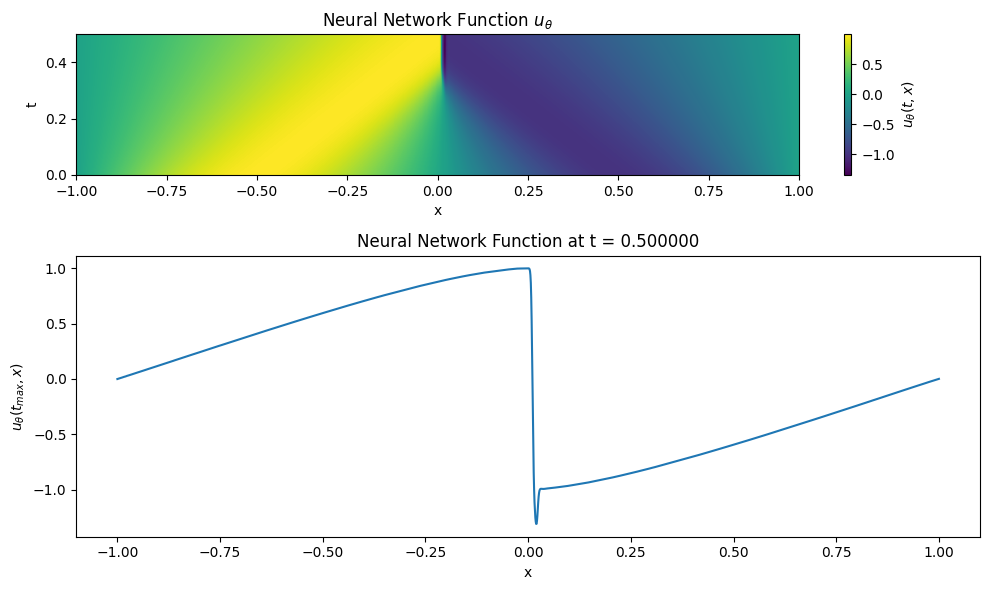

Adding grade 1 with hidden dims [64, 64, 64, 64]

Plotting before training segment [0.5000, 1.0000]


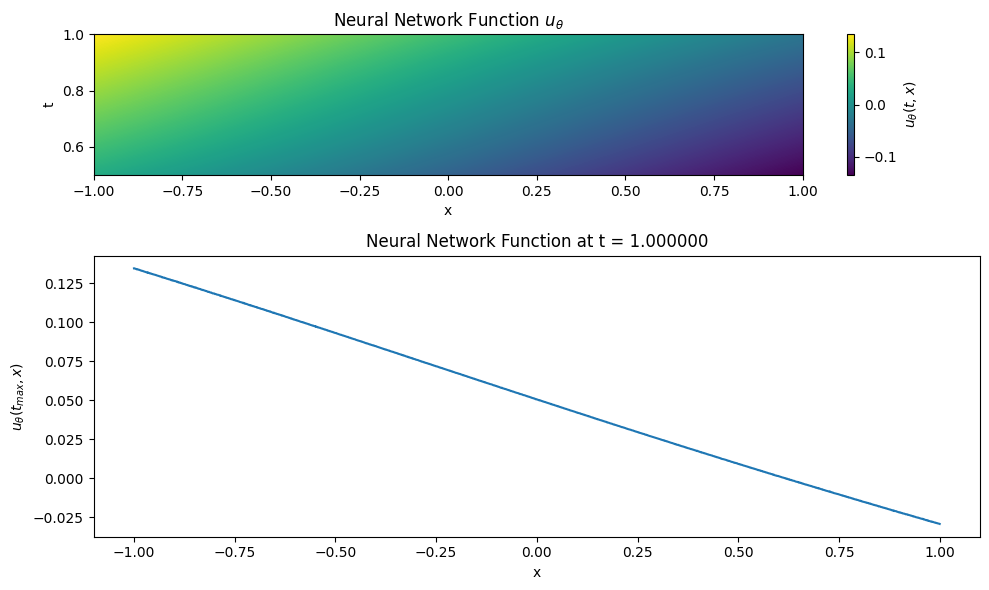


Training segment [0.5000, 1.0000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, loss_eqn: 0.204574, loss_eqn_from_kh: 0.204573, loss_eqn_abs: 0.204573, loss_ibc: 0.403934
Grade 0, Iter 100, loss_eqn: 0.533263, loss_eqn_from_kh: 0.533241, loss_eqn_abs: 0.533241, loss_ibc: 0.071674
Grade 0, Iter 200, loss_eqn: 0.362074, loss_eqn_from_kh: 0.362073, loss_eqn_abs: 0.362275, loss_ibc: 0.021846
Grade 0, Iter 300, loss_eqn: 0.307649, loss_eqn_from_kh: 0.307640, loss_eqn_abs: 0.366557, loss_ibc: 0.010986
Grade 0, Iter 400, loss_eqn: 0.210406, loss_eqn_from_kh: 0.210382, loss_eqn_abs: 0.384889, loss_ibc: 0.004316
Grade 0, Iter 500, loss_eqn: 0.127627, loss_eqn_from_kh: 0.127627, loss_eqn_abs: 0.394326, loss_ibc: 0.003175
Grade 0, Iter 600, loss_eqn: 0.123507, loss_eqn_from_kh: 0.123491, loss_eqn_abs: 0.452249, loss_ibc: 0.001790
Grade 0, Iter 700, loss_eqn: 0.081777, loss_eqn_from_kh: 0.081702, loss_eqn_abs: 0.516065, loss_ibc: 0.000785
G

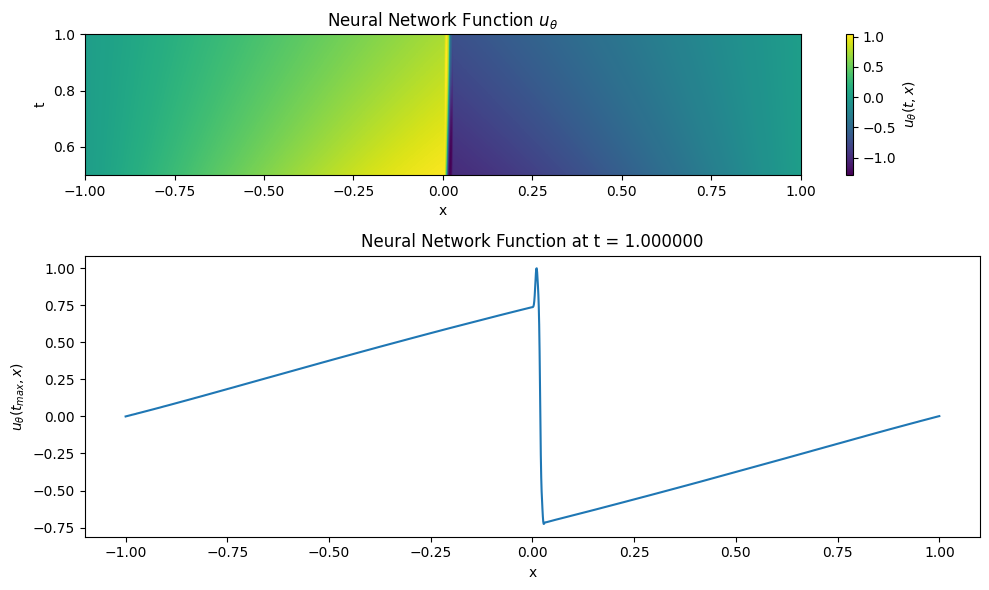


Plotting combined output across all segments from t=0 to total_t_max


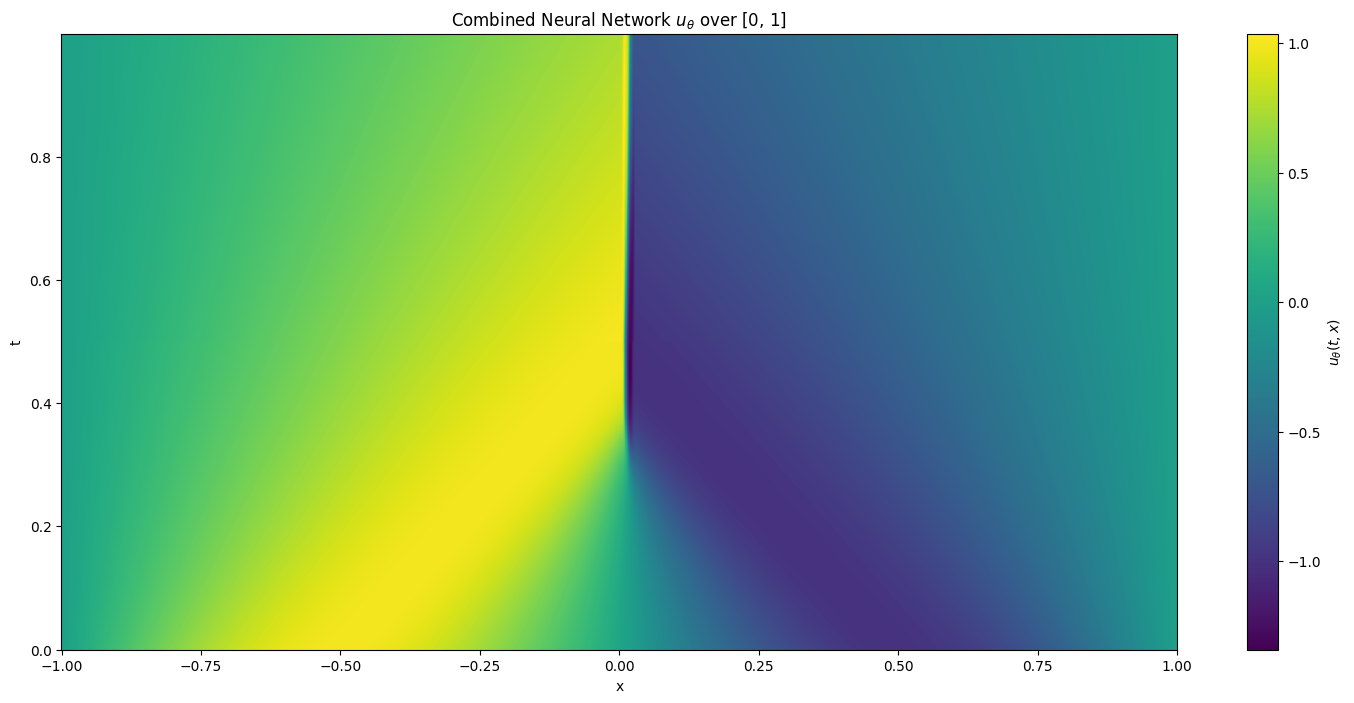

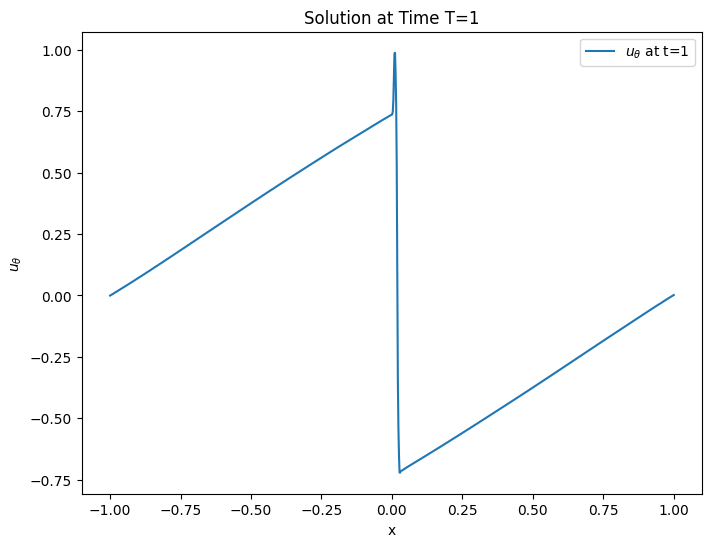

step,▁▁▂▂▂▃▃▄▄▅▅▅▆▆▆▆▇▇▇▇█▁▁▂▂▃▃▃▃▄▅▅▅▆▆▆▇▇▇█
tmin0.0_tmax0.5_loss_eqn_grade0,█▃▃▃▂▂▂▂▁▂▂▂▁▁▁▁▁▁▁▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.0_tmax0.5_loss_ibc_grade0,██▆▇▅▆▄▃▃▂▂▂▂▂▂▂▂▁▂▁▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_eqn_grade0,█▇▃▃▃▄▃▃▃▃▂▂▂▁▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_ibc_grade0,█▃▂▂▂▂▂▃▂▁▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,9900
tmin0.0_tmax0.5_loss_eqn_grade0,0.00282
tmin0.0_tmax0.5_loss_ibc_grade0,0.0003
tmin0.5_tmax1.0_loss_eqn_grade0,0.00131
tmin0.5_tmax1.0_loss_ibc_grade0,1e-05


In [ ]:
seq_trainer.train_seq()

Adding grade 1 with hidden dims [128, 128, 128, 128]

Plotting before training segment [0.0000, 0.5000]


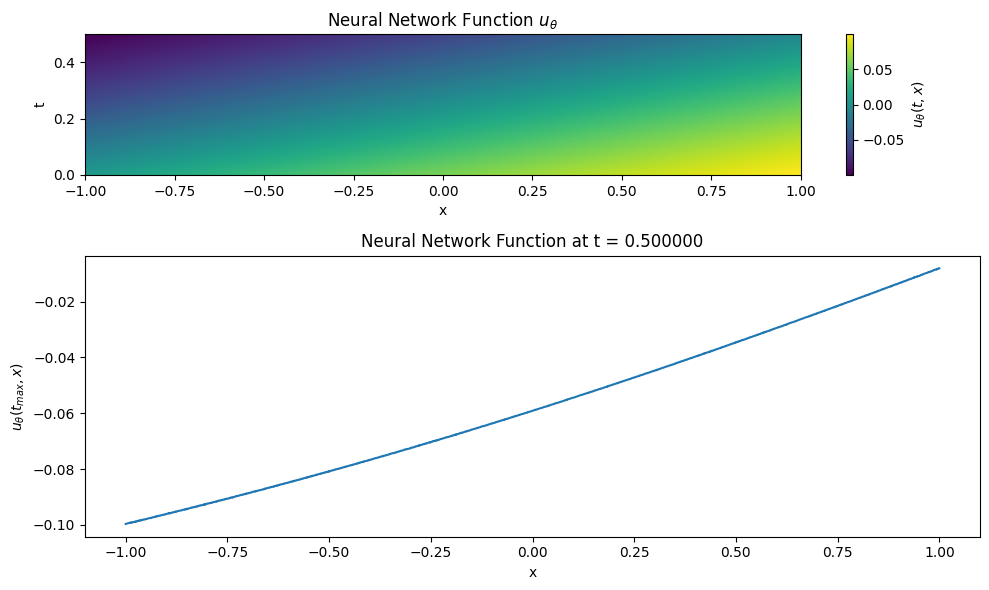


Training segment [0.0000, 0.5000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 9.730865, lambda_bc: 11.067774, lambda_eqn: 1.022727
Grade 0, Iter 0, loss_eqn: 0.228407, loss_eqn_from_kh: 0.228406, loss_eqn_abs: 0.228406, loss_ibc: 0.539963
Grade 0, Iter 100, loss_eqn: 0.118376, loss_eqn_from_kh: 0.118376, loss_eqn_abs: 0.118376, loss_ibc: 0.413318
Grade 0, Iter 200, loss_eqn: 0.444869, loss_eqn_from_kh: 0.444853, loss_eqn_abs: 0.444853, loss_ibc: 0.024301
Grade 0, Iter 300, loss_eqn: 0.331100, loss_eqn_from_kh: 0.331097, loss_eqn_abs: 0.331100, loss_ibc: 0.013102
Grade 0, Iter 400, loss_eqn: 0.251201, loss_eqn_from_kh: 0.251169, loss_eqn_abs: 0.251171, loss_ibc: 0.006061
Grade 0, Iter 500, loss_eqn: 0.205935, loss_eqn_from_kh: 0.205881, loss_eqn_abs: 0.205883, loss_ibc: 0.008408
Grade 0, Iter 600, loss_eqn: 0.177965, loss_eqn_from_kh: 0.177884, loss_eqn_abs: 0.177892, loss_ibc: 0.008008
Grade 0, Iter 700, loss_eqn: 0

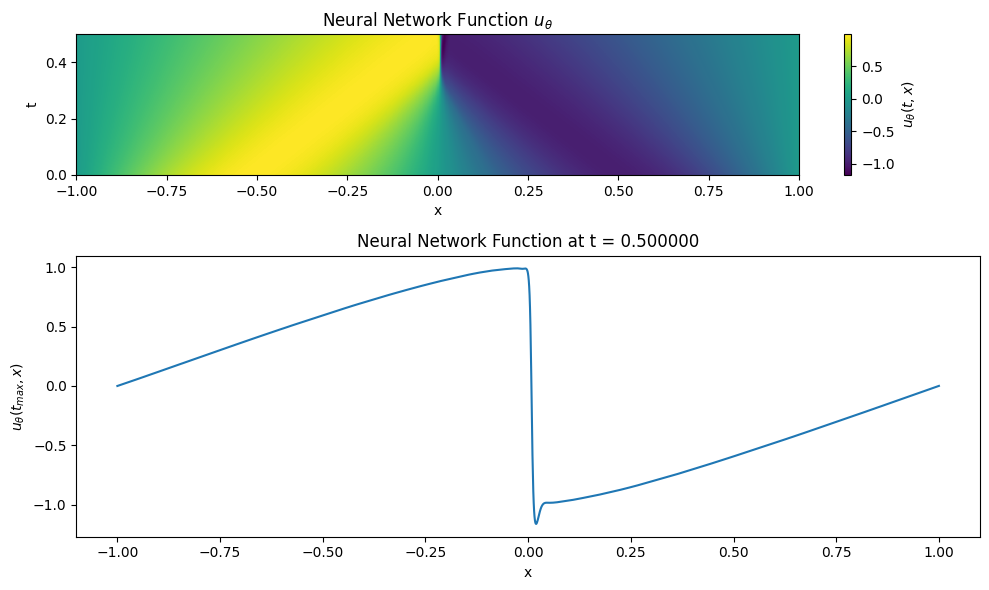

Adding grade 1 with hidden dims [128, 128, 128, 128]

Plotting before training segment [0.5000, 1.0000]


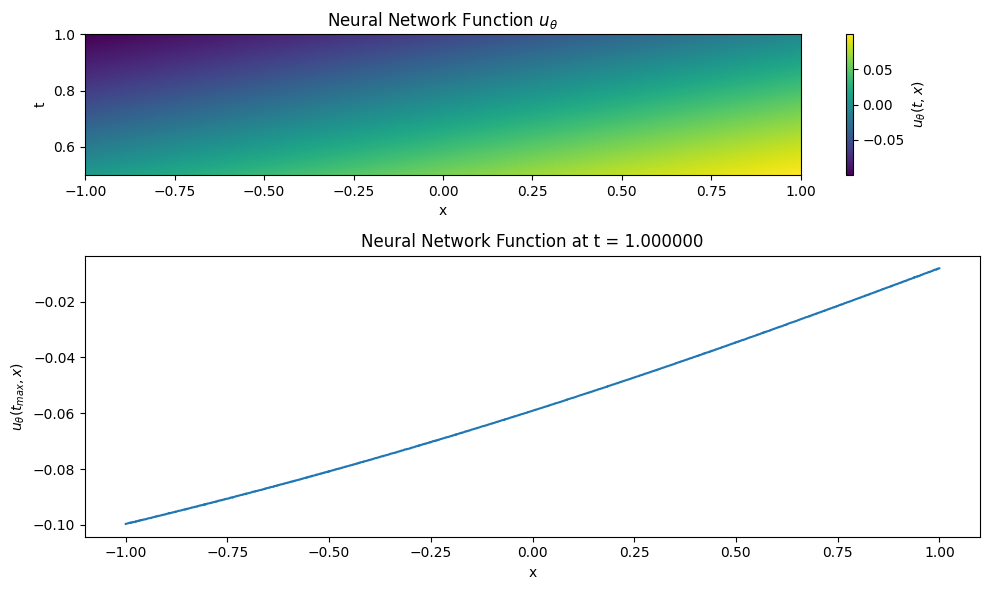


Training segment [0.5000, 1.0000]

Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 10.052274, lambda_bc: 10.972286, lambda_eqn: 1.017060
Grade 0, Iter 0, loss_eqn: 0.228312, loss_eqn_from_kh: 0.228311, loss_eqn_abs: 0.228311, loss_ibc: 0.441596
Grade 0, Iter 100, loss_eqn: 0.042523, loss_eqn_from_kh: 0.042523, loss_eqn_abs: 0.042523, loss_ibc: 0.388595
Grade 0, Iter 200, loss_eqn: 0.397959, loss_eqn_from_kh: 0.397958, loss_eqn_abs: 0.397961, loss_ibc: 0.034705
Grade 0, Iter 300, loss_eqn: 0.372731, loss_eqn_from_kh: 0.372731, loss_eqn_abs: 0.374337, loss_ibc: 0.020366
Grade 0, Iter 400, loss_eqn: 0.318711, loss_eqn_from_kh: 0.318715, loss_eqn_abs: 0.355654, loss_ibc: 0.010995
Grade 0, Iter 500, loss_eqn: 0.249740, loss_eqn_from_kh: 0.249731, loss_eqn_abs: 0.356658, loss_ibc: 0.009161
Grade 0, Iter 600, loss_eqn: 0.160777, loss_eqn_from_kh: 0.160774, loss_eqn_abs: 0.369635, loss_ibc: 0.003030
Grade 0, Iter 700, loss_eqn: 

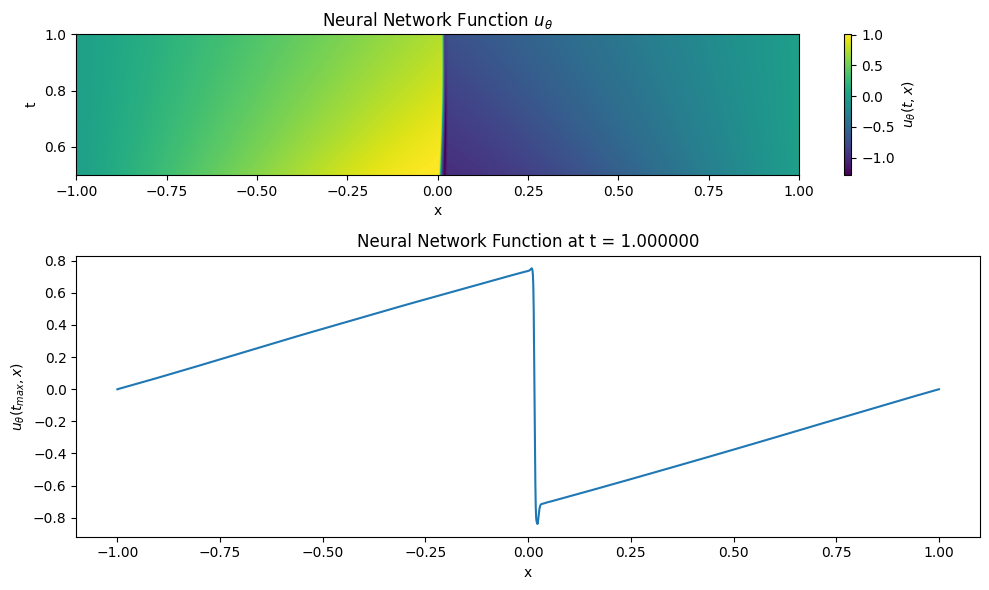


Plotting combined output across all segments from t=0 to total_t_max


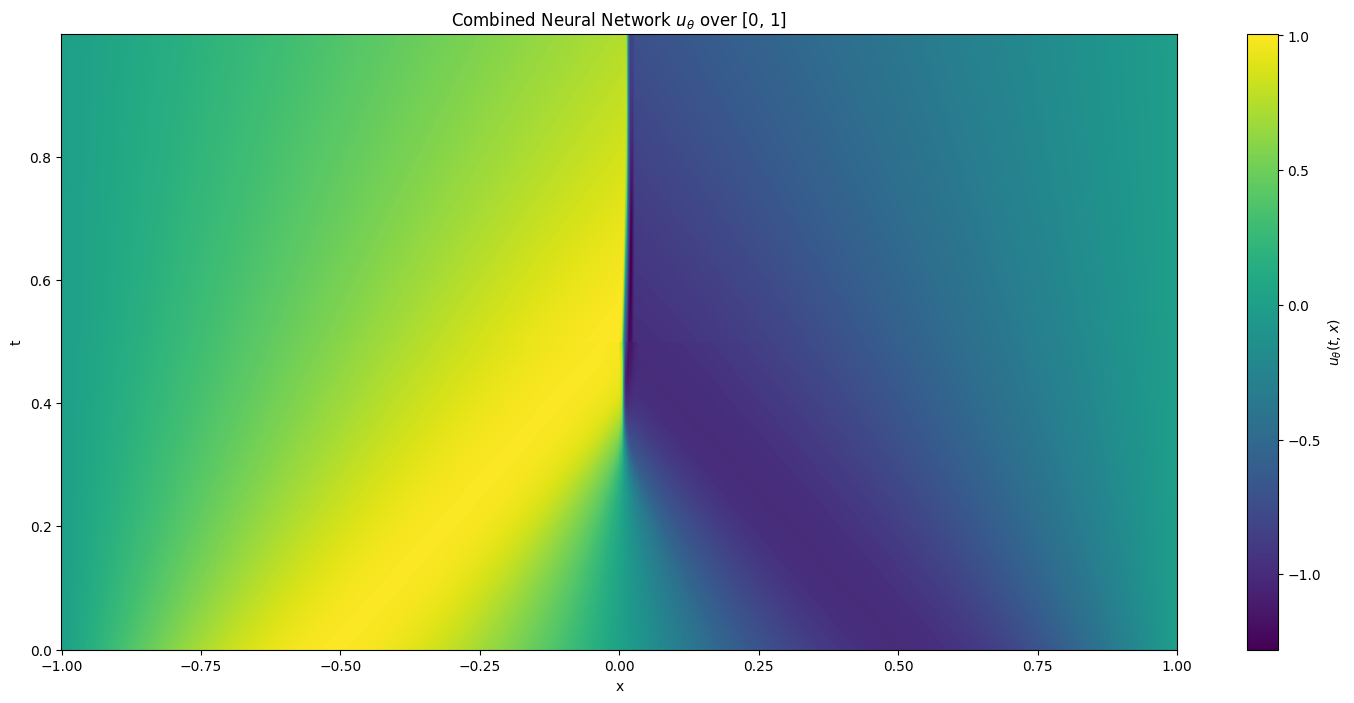

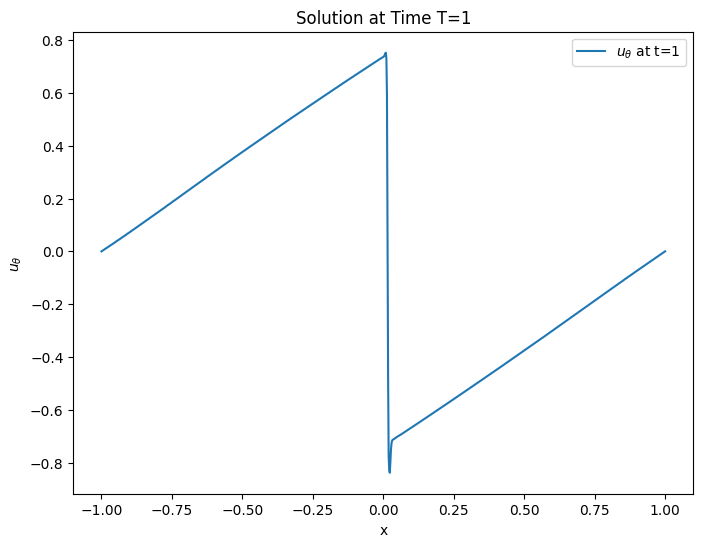

step,▁▁▂▂▂▃▃▃▃▄▄▅▅▅▅▆▇▇▇█▁▁▁▁▂▂▃▃▃▄▅▅▅▅▆▆▇▇██
tmin0.0_tmax0.5_loss_eqn_grade0,▄▃█▆▅▄▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.0_tmax0.5_loss_ibc_grade0,█▆▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_eqn_grade0,▅▂██▇▄▃▃▂▄▃▃▃▄▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
tmin0.5_tmax1.0_loss_ibc_grade0,█▇▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,4900
tmin0.0_tmax0.5_loss_eqn_grade0,0.01869
tmin0.0_tmax0.5_loss_ibc_grade0,0.00017
tmin0.5_tmax1.0_loss_eqn_grade0,0.0059
tmin0.5_tmax1.0_loss_ibc_grade0,0.0001


In [ ]:
seq_trainer.train_seq()

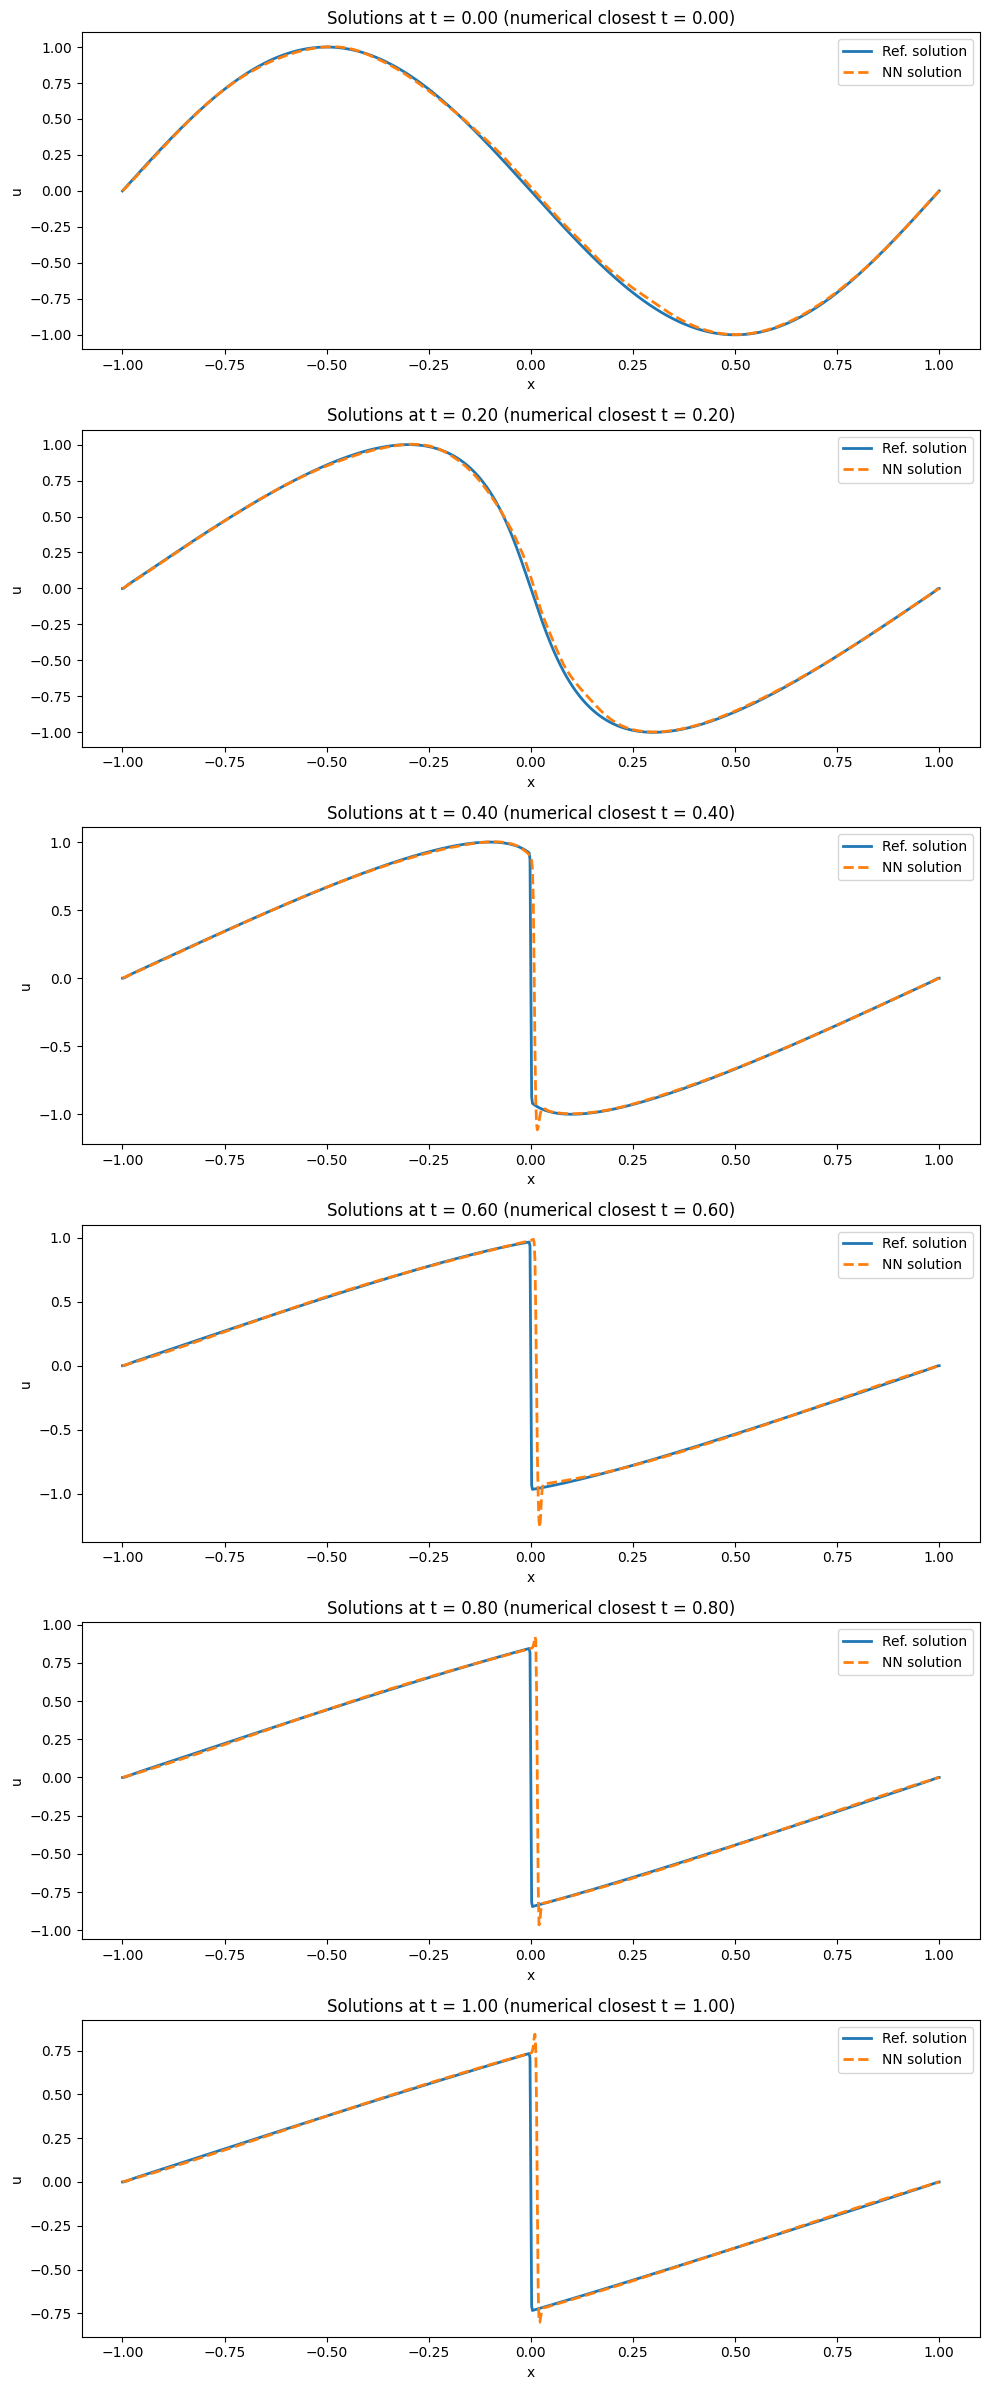

In [ ]:
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta
plot_comparison_seperate_combined_u_theta(seq_trainer, ts=[0.2*i for i in range(6)])

In [ ]:
compute_errors_combined_u_theta(seq_trainer)

Relative error at T: 0.041117876515388604
Space-time relative error: 0.026084324864206934


(np.float64(0.041117876515388604), np.float64(0.026084324864206934))

In [ ]:
data = np.load('data/burgers_sin_ref.npz')
times = data['times']
x = data['x']
u_num = data['u']  # Shape: (n_times, n_x)

In [ ]:
times[-1]

In [ ]:
idx_T = np.argmin(np.abs(times - 1.0))

In [ ]:
idx_T

In [ ]:
def plot_combined_u_theta(self, M_t_per_segment=1000, M_x=2000, upload_fig=False):
        """
        Plot the combined output of all trained segments over the full time domain [0, total_t_max].

        Args:
            M_t_per_segment (int): Number of grid points in t per segment.
            M_x (int): Number of grid points in x.
        """
        # Generate time grids for each segment based on self.seq_T
        t_grids = []
        for i in range(self.num_segments):
            t_min = self.seq_T[i]
            t_max = self.seq_T[i + 1]
            t_segment = jnp.linspace(t_min, t_max, M_t_per_segment+1)[:-1]
            t_grids.append(t_segment)

        # Concatenate all segment time grids into a full time grid
        t_grid_full = jnp.concatenate(t_grids)
        # Create the spatial grid
        x_grid = jnp.linspace(self.x_min, self.x_max, M_x)

        # Create a meshgrid for t and x
        t, x = jnp.meshgrid(t_grid_full, x_grid, indexing='ij')  # Shapes: (total_M_t, M_x)

        # Flatten the grid for evaluation
        tx_points_full = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (total_M_t * M_x, 2)

        # Determine which segment each time point belongs to
        segment_indices = jnp.digitize(tx_points_full[:, 0], self.seq_T) - 1
        segment_indices = jnp.clip(segment_indices, 0, self.num_segments - 1)

        # Collect outputs from each segment
        u_values_full = []
        for i in range(self.num_segments):
            mask = (segment_indices == i)
            tx_points_segment = tx_points_full[mask]
            if tx_points_segment.size > 0:
                segment = self.segments[i]
                u_values_segment = segment.model.forward(tx_points_segment)
                u_values_full.append(u_values_segment)

        # Combine all segment outputs into a single array
        u_values_full = jnp.concatenate(u_values_full)
        u_values_full = u_values_full.reshape(len(t_grid_full), M_x)

        # Create the plot
        t_range = self.total_t_max - self.total_t_min
        fig = plt.figure(figsize=(10, 4 + 4 * t_range))
        gs = gridspec.GridSpec(2, 1, height_ratios=[t_range, 1])
        ax1 = fig.add_subplot(gs[0])
        ax2 = fig.add_subplot(gs[1])

        # 2D color mesh plot
        pcm = ax1.pcolormesh(x_grid, t_grid_full, u_values_full, shading='nearest', cmap='viridis')
        fig.colorbar(pcm, ax=ax1, label='$u_\\theta(t, x)$')
        ax1.set_xlabel('x')
        ax1.set_ylabel('t')
        ax1.set_title(f'Combined Neural Network $u_\\theta$ over [{self.total_t_min}, {self.total_t_max}]')

        # 1D plot at t = t_max
        # Get the last segment
        segment = self.segments[-1]
        t_jnp = jnp.full_like(x_grid, self.total_t_max)
        tx_points_max = jnp.stack([t_jnp, x_grid], axis=1)  # Shape: (M_x, 2)
        u_at_max = segment.model.forward(tx_points_max)
        ax2.plot(x_grid, u_at_max)
        ax2.set_xlabel('x')
        ax2.set_ylabel('$u_\\theta(t_{max}, x)$')
        ax2.set_title(f'Neural Network Function at t = {self.total_t_max:.2f}')

        # Adjust layout and display the main plot
        plt.tight_layout()
        # Upload the figure to wandb
        plt.show()

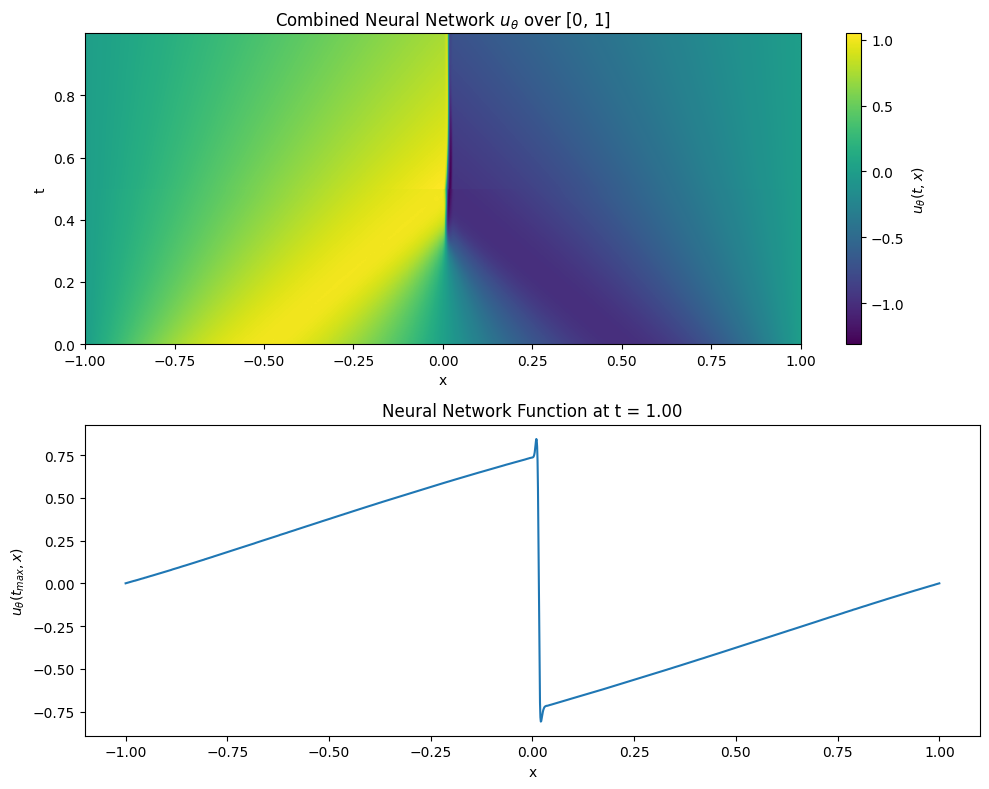

In [ ]:
seq_trainer.plot_combined_u_theta()